# Scratch: section 7 (outliers)

This is my working notebook for section 7. It reads the labeled data built by EDA_Preprocessing.ipynb.

First we list the columns to check the fix. Labels in the last 30 days should now be blank for every drive, so the late June dates should have 0 labeled rows while May 15 looks normal.

In [1]:
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

con = duckdb.connect()
PATH = "../data/labeled.parquet"

print(con.sql(f"DESCRIBE SELECT * FROM '{PATH}'").df()[["column_name", "column_type"]])

con.sql(f"""
    SELECT date,
           COUNT(label_30d) AS labeled_rows,
           SUM(label_30d)   AS positive_rows
    FROM '{PATH}'
    WHERE date IN (DATE '2026-05-15', DATE '2026-06-10', DATE '2026-06-20', DATE '2026-06-29')
    GROUP BY date
    ORDER BY date
""").df()

        column_name column_type
0              date        DATE
1     serial_number     VARCHAR
2             model     VARCHAR
3    capacity_bytes      BIGINT
4           failure     INTEGER
..              ...         ...
79    smart_242_raw      DOUBLE
80  days_to_failure      BIGINT
81         label_3d     INTEGER
82         label_7d     INTEGER
83        label_30d     INTEGER

[84 rows x 2 columns]


,date,labeled_rows,positive_rows
0,2026-05-15,13005,26.0
1,2026-06-10,0,NaN
2,2026-06-20,0,NaN
3,2026-06-29,0,NaN


# Load the usable rows

We only keep rows with a 30-day label and summarize the five main columns. The error counters (5, 197, 198) are 0 for 95% to 98% of rows, with a few huge values. Power-on hours (9) and temperature (194) look normal. This is why one outlier rule can't fit every column.

In [2]:
COLS = ["smart_5_raw", "smart_9_raw", "smart_194_raw", "smart_197_raw", "smart_198_raw"]

df = con.sql(f"""
    SELECT date, serial_number, model, label_30d, {", ".join(COLS)}
    FROM '{PATH}'
    WHERE label_30d IS NOT NULL
""").df()

print("usable rows:", len(df))
print("rows with all five readings:", len(df.dropna(subset=COLS)))
print("base rate (% positive):", round(100 * df.label_30d.mean(), 3))
print()

summary = df[COLS].describe(percentiles=[0.5, 0.75, 0.99]).T
summary["pct_zero"] = (100 * (df[COLS] == 0).mean()).round(1)
summary.round(1)

usable rows: 1986219
rows with all five readings: 1986204
base rate (% positive): 0.185



,count,mean,std,min,50%,75%,99%,max,pct_zero
smart_5_raw,1986204.0,53.9,1099.8,0.0,0.0,0.0,136.0,64784.0,95.6
smart_9_raw,1986204.0,49865.1,8036.8,3.0,49981.0,54917.0,65681.0,69337.0,0.0
smart_194_raw,1986204.0,32.4,5.2,15.0,33.0,36.0,43.0,60.0,0.0
smart_197_raw,1986204.0,2.1,75.3,0.0,0.0,0.0,14.0,63832.0,97.3
smart_198_raw,1986204.0,3.0,73.4,0.0,0.0,0.0,25.0,63832.0,97.8


# First try: flag outliers in five columns

For the counters, the 25th and 75th percentiles are both 0 so the IQR is also 0 therfore we flag any reading above 0 instead. For age and temperature we use the 1.5 × IQR rule within each model.

The lift is the share of flagged rows within 30 days of a failure divided by the base rate of 0.185%. A lift of 1 means the flag tells us nothing.

In [3]:
df = df.dropna(subset=COLS).copy()

# counters: any non-zero reading counts as unusual
for c in ["smart_5_raw", "smart_197_raw", "smart_198_raw"]:
    df[c + "_out"] = df[c] > 0

# power-on hours and temperature: 1.5 x IQR rule, separately for each model
for c in ["smart_9_raw", "smart_194_raw"]:
    q1 = df.groupby("model")[c].transform(lambda s: s.quantile(0.25))
    q3 = df.groupby("model")[c].transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    df[c + "_out"] = (df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)

out_cols = [c + "_out" for c in COLS]
df["any_out"] = df[out_cols].any(axis=1)

base = df.label_30d.mean()
rows = []
for c in out_cols + ["any_out"]:
    f = df[c]
    rows.append({
        "flag": c,
        "pct_rows_flagged": round(100 * f.mean(), 2),
        "pct_in_failure_window_if_flagged": round(100 * df.loc[f, "label_30d"].mean(), 2),
        "pct_in_failure_window_if_not": round(100 * df.loc[~f, "label_30d"].mean(), 2),
        "lift": round(df.loc[f, "label_30d"].mean() / base, 1),
    })
pd.DataFrame(rows)

,flag,pct_rows_flagged,pct_in_failure_window_if_flagged,pct_in_failure_window_if_not,lift
0,smart_5_raw_out,4.38,2.77,0.07,15.0
1,smart_9_raw_out,4.25,0.22,0.18,1.2
2,smart_194_raw_out,1.08,0.41,0.18,2.2
3,smart_197_raw_out,2.72,4.55,0.06,24.7
4,smart_198_raw_out,2.17,4.84,0.08,26.3
5,any_out,10.92,1.41,0.03,7.7


# First figure

Left: The lift of each flag. Right: SMART 197 against 198 for rows with any error with rows just before a failure in red. Matteo's box plots and heatmap already show what the right panel shows so i can remove the right panel.

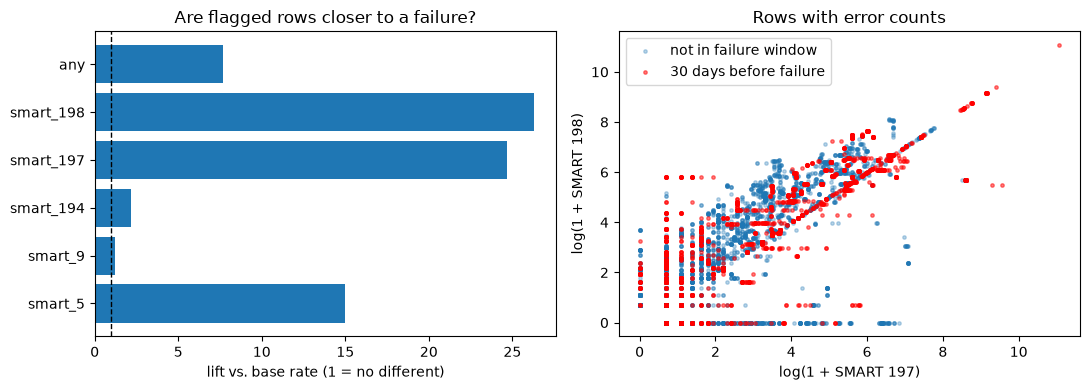

share of failure-window rows flagged by any_out: 83.8 %


In [4]:
res = pd.DataFrame(rows).set_index("flag")
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# left: lift for each flag
labels = res.index.str.replace("_raw_out", "").str.replace("_out", "")
ax[0].barh(labels, res["lift"])
ax[0].axvline(1, color="black", lw=1, ls="--")
ax[0].set_xlabel("lift vs. base rate (1 = no different)")
ax[0].set_title("Are flagged rows closer to a failure?")

# right: SMART 197 vs 198 for rows that have any error, failure-window rows in red
err = df[(df.smart_197_raw > 0) | (df.smart_198_raw > 0)]
healthy = err[err.label_30d == 0].sample(5000, random_state=0)
fail = err[err.label_30d == 1]
ax[1].scatter(np.log1p(healthy.smart_197_raw), np.log1p(healthy.smart_198_raw),
              s=6, alpha=0.3, label="not in failure window")
ax[1].scatter(np.log1p(fail.smart_197_raw), np.log1p(fail.smart_198_raw),
              s=6, alpha=0.5, color="red", label="30 days before failure")
ax[1].set_xlabel("log(1 + SMART 197)")
ax[1].set_ylabel("log(1 + SMART 198)")
ax[1].set_title("Rows with error counts")
ax[1].legend()
plt.tight_layout()
plt.show()

print("share of failure-window rows flagged by any_out:",
      round(100 * df.loc[df.label_30d == 1, "any_out"].mean(), 1), "%")

# Final version: seven columns

We add 187 and 188 to match Matteo's section 5. Only the Seagate model reports them (28% of rows) so their lifts use only those rows.

Result: The counters have lifts of 6 to 26 while age and temperature are near 1 and 2. The outliers are where the failures are so we keep them. Limits: About 95% of flagged rows are still healthy, 12.8% of failure-window rows aren't flagged at all and the positive rows come from only 168 drives.

rows: 1986204
share with a reading (%):
smart_5_raw      100.0
smart_187_raw     28.2
smart_188_raw     28.2
smart_197_raw    100.0
smart_198_raw    100.0
smart_9_raw      100.0
smart_194_raw    100.0
dtype: float64


,pct_rows_flagged,pct_in_failure_window_if_flagged,pct_in_failure_window_if_not,lift
flag,,,,
smart_5_raw_out,4.38,2.77,0.07,15.0
smart_187_raw_out,4.18,3.26,0.07,17.7
smart_188_raw_out,9.99,1.10,0.11,6.0
smart_197_raw_out,2.72,4.55,0.06,24.7
smart_198_raw_out,2.17,4.84,0.08,26.3
smart_9_raw_out,4.25,0.22,0.18,1.2
smart_194_raw_out,1.08,0.41,0.18,2.2
any_out,13.42,1.20,0.03,6.5


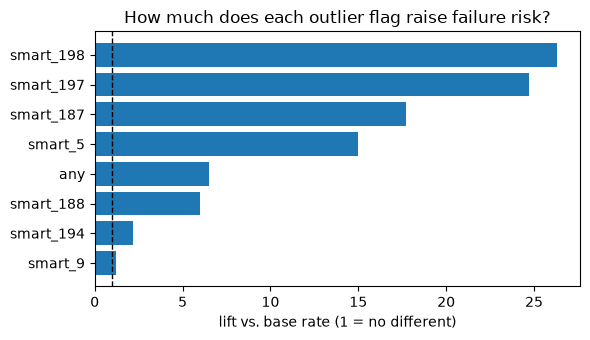

share of failure-window rows flagged by any_out: 87.2 %


In [5]:
COUNTERS = ["smart_5_raw", "smart_187_raw", "smart_188_raw", "smart_197_raw", "smart_198_raw"]
CONTINUOUS = ["smart_9_raw", "smart_194_raw"]
ALL = COUNTERS + CONTINUOUS

df = con.sql(f"""
    SELECT model, label_30d, {", ".join(ALL)}
    FROM '{PATH}'
    WHERE label_30d IS NOT NULL
""").df()
df = df.dropna(subset=COLS).copy()   # same rows as before

print("rows:", len(df))
print("share with a reading (%):")
print((100 * df[ALL].notna().mean()).round(1))

for c in COUNTERS:
    df[c + "_out"] = df[c] > 0       # missing readings count as not flagged
for c in CONTINUOUS:
    q1 = df.groupby("model")[c].transform(lambda s: s.quantile(0.25))
    q3 = df.groupby("model")[c].transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    df[c + "_out"] = (df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)

out_cols = [c + "_out" for c in ALL]
df["any_out"] = df[out_cols].any(axis=1)

base = df.label_30d.mean()
rows = []
for c in out_cols + ["any_out"]:
    has = df[c.replace("_out", "")].notna() if c != "any_out" else pd.Series(True, index=df.index)
    f = df[c] & has
    rows.append({
        "flag": c,
        "pct_rows_flagged": round(100 * f[has].mean(), 2),
        "pct_in_failure_window_if_flagged": round(100 * df.loc[f, "label_30d"].mean(), 2),
        "pct_in_failure_window_if_not": round(100 * df.loc[has & ~f, "label_30d"].mean(), 2),
        "lift": round(df.loc[f, "label_30d"].mean() / base, 1),
    })
res = pd.DataFrame(rows).set_index("flag")
display(res)

fig, ax = plt.subplots(figsize=(6, 3.5))
s = res["lift"].sort_values()
ax.barh(s.index.str.replace("_raw_out", "").str.replace("_out", ""), s)
ax.axvline(1, color="black", lw=1, ls="--")
ax.set_xlabel("lift vs. base rate (1 = no different)")
ax.set_title("How much does each outlier flag raise failure risk?")
plt.tight_layout()
plt.show()

print("share of failure-window rows flagged by any_out:",
      round(100 * df.loc[df.label_30d == 1, "any_out"].mean(), 1), "%")